# 2. modell – Embedding + Bidirectional(LSTM)

**Architektúra:** `Embedding(mask_zero=True) → Bidirectional(LSTM(64)) → Dropout → Dense(1, sigmoid)`

Az adat-előkészítés, a felosztás, a tokenizer és a kiértékelés a közös `dl_prep.py`-ból jön, ugyanúgy, mint a többi DL modellnél (lásd `dl_1_baseline.ipynb`):
- cikkenkénti GroupShuffleSplit (random_state=42), a test **csak a legvégén** kerül elő,
- a train-ből 12% (cikkenként) a validációs halmaz, erre figyel az EarlyStopping,
- egy tokenizer, csak a train szövegeken illesztve, `num_words=20 000`, `maxlen` = 95. percentilis.

Az LSTM a mondatot szóról szóra olvassa, és egy belső állapotban (cella + rejtett állapot) gyűjti a kontextust. A `Bidirectional` réteg két LSTM-et futtat: egyet balról jobbra, egyet jobbról balra, és a két végállapotot összefűzi (64 egység → 128 dimenziós mondatvektor). A `mask_zero=True` miatt a padding-nullákat az LSTM átugorja.

**Kísérletek** (mindegyik a *validációs* halmazon, 3 seed – 42, 43, 44 – átlaga):
1. Sima `LSTM` vs. `Bidirectional(LSTM)`.
2. Egységszám: 32 / 64 / 128.
3. Regularizáció: a külön `Dropout` réteg aránya (0 / 0,3 / 0,5), illetve az LSTM saját `dropout` (bemeneti) és `recurrent_dropout` (állapot-) paramétere a Dropout réteg mellett.
4. Tanulási görbe Dropout nélkül és Dropouttal, EarlyStopping nélkül 30 epochon.

**Közös beállítások Attilával (GRU, `dl_4_bigru.ipynb`)**, hogy az LSTM és a GRU összevethető legyen: `EMBED_DIM=100`, `BATCH_SIZE=64` (a `dl_prep`-ből), `mask_zero=True`, alapbeállításként **64 egység, Dropout 0,3**, Adam lr=1e-3, EarlyStopping patience=3. Ugyanezt a három egységszámot (32/64/128) mérjük. A végén külön elmentjük a közös (64 egység, Dropout 0,3) beállítás val-eredményét is, ez kerül az LSTM vs. GRU táblába.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import dl_prep as dp

SEEDS = [42, 43, 44]
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "nincs (CPU)")
data = dp.load_data()
print(data.summary())

I0000 00:00:1794911314.293628    2102 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794911314.350920    2102 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794911315.507005    2102 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


train: 10370 mondat (527 cikk) | val: 1446 (72 cikk) | test: 3048 (150 cikk)
szókincs (train): 11893 szó, ebből használt: 11894 index | maxlen: 48 token


### Modell és segédfüggvények
- `bidirectional=False` → sima, egyirányú LSTM (1. kísérlet).
- `dropout` → a külön `Dropout` réteg az LSTM után.
- `lstm_dropout` / `recurrent_dropout` → az LSTM saját paraméterei: a bemenetre, illetve az időlépések közti állapotra alkalmazott dropout. **Figyelem:** `recurrent_dropout > 0` esetén a Keras nem tudja a gyors cuDNN-kernelt használni, ezért a tanítás GPU-n jóval lassabb.

In [2]:
def build_model(units=64, bidirectional=True, dropout=0.3, lstm_dropout=0.0, recurrent_dropout=0.0):
    lstm = layers.LSTM(units, dropout=lstm_dropout, recurrent_dropout=recurrent_dropout)
    model = keras.Sequential([
        keras.Input(shape=(data.maxlen,)),
        layers.Embedding(data.vocab_size, dp.EMBED_DIM, mask_zero=True),
        layers.Bidirectional(lstm) if bidirectional else lstm,
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ], name="bilstm" if bidirectional else "lstm")
    return dp.compile_model(model)


DEFAULTS = dict(units=64, bidirectional=True, dropout=0.3, lstm_dropout=0.0, recurrent_dropout=0.0)


def run_config(label, seeds=SEEDS, **params):
    """Egy beállítás tanítása több seeddel; a validációs metrikák átlaga és szórása."""
    params = {**DEFAULTS, **params}
    rows, histories = [], {}
    for seed in seeds:
        dp.set_seeds(seed)
        model = build_model(**params)
        history, seconds = dp.fit(model, data)
        r = dp.evaluate(model, data, split="val")
        rows.append({"val_acc": r["accuracy"], "val_f1": r["f1"],
                     "val_loss": min(history.history["val_loss"]),
                     "best_epoch": dp.best_epoch(history), "epochs": len(history.history["loss"]),
                     "sec": seconds})
        histories[seed] = history
    df = pd.DataFrame(rows)
    summary = {"beállítás": label, **params, "paraméterek": model.count_params(),
               "val_acc": df.val_acc.mean(), "±acc": df.val_acc.std(),
               "val_f1": df.val_f1.mean(), "val_loss": df.val_loss.mean(),
               "legjobb epoch": df.best_epoch.mean(), "idő (s)": df.sec.mean(),
               "s/epoch": (df.sec / df.epochs).mean()}
    print(f"{label:38s} val_acc {summary['val_acc']:.4f} ± {summary['±acc']:.4f}  idő {summary['idő (s)']:.1f} s")
    return summary, histories[seeds[0]]


SHOW = ["beállítás", "paraméterek", "val_acc", "±acc", "val_f1", "val_loss", "legjobb epoch", "idő (s)", "s/epoch"]
fmt = {"paraméterek": "{:,}", "val_acc": "{:.4f}", "±acc": "{:.4f}", "val_f1": "{:.4f}", "val_loss": "{:.4f}",
       "legjobb epoch": "{:.1f}", "idő (s)": "{:.1f}", "s/epoch": "{:.2f}"}
show = lambda df: display(df[SHOW].style.format(fmt).hide(axis="index"))

dp.set_seeds(); build_model().summary()

I0000 00:00:1794911318.909039    2102 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 48, 100)        │     1,189,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,274,009 (4.86 MB)

 Trainable params: 1,274,009 (4.86 MB)

 Non-trainable params: 0 (0.00 B)

## 1. kísérlet: sima LSTM vs. Bidirectional LSTM
Mindkettő 64 egységes, Dropout 0,3. A kétirányú változatnak kétszer annyi LSTM-paramétere van, és a mondat elejéről is „friss” információt kap (a hátrafelé futó LSTM végállapota a mondat elejénél van).

I0000 00:00:1794911321.486753    2202 cuda_dnn.cc:461] Loaded cuDNN version 92801


LSTM(64)                               val_acc 0.7778 ± 0.0044  idő 15.1 s


Bidirectional(LSTM(64))                val_acc 0.7833 ± 0.0033  idő 19.8 s


beállítás,paraméterek,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s),s/epoch
LSTM(64),"1,231,705",0.7778,0.0044,0.7624,0.4579,1.0,15.1,3.78
Bidirectional(LSTM(64)),"1,274,009",0.7833,0.0033,0.7703,0.4530,1.0,19.8,4.95


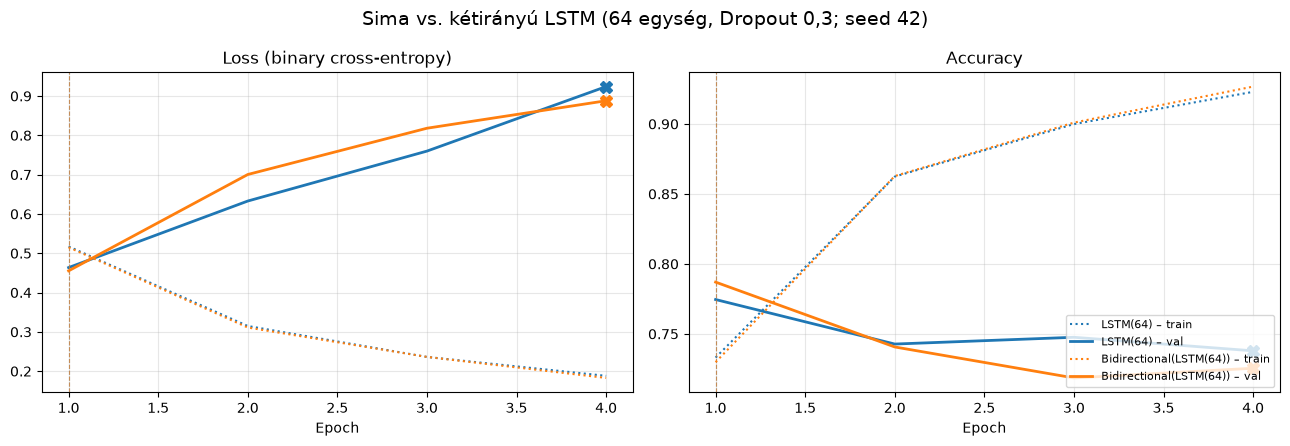

In [3]:
exp1, exp1_hist = [], {}
for bi in [False, True]:
    label = "Bidirectional(LSTM(64))" if bi else "LSTM(64)"
    s, h = run_config(label, bidirectional=bi)
    exp1.append(s); exp1_hist[label] = h
exp1 = pd.DataFrame(exp1)
show(exp1)
dp.plot_history(exp1_hist, "Sima vs. kétirányú LSTM (64 egység, Dropout 0,3; seed 42)"); plt.show()

**Eredmény:** a kétirányú LSTM kicsit jobb (val_acc 0,783 vs. 0,778), de a különbség (~0,5 százalékpont) alig nagyobb a seedek közti szórásnál (±0,003–0,004). Az ára ~31% több idő (19,8 s vs. 15,1 s) és kétszer annyi LSTM-paraméter (84 480 vs. 42 240). A továbbiakban a Bidirectional változattal dolgozunk.

## 2. kísérlet: egységszám (32 / 64 / 128)
Az irányt az 1. kísérlet alapján választjuk (a magasabb átlagos val_acc nyer). Ugyanezt a hármat méri Attila a GRU-nál.

In [4]:
best_bi = bool(exp1.sort_values("val_acc", ascending=False).iloc[0]["bidirectional"])
print("Választott irány:", "Bidirectional" if best_bi else "egyirányú")

exp2, exp2_hist = [], {}
for units in [32, 64, 128]:
    s, h = run_config(f"{units} egység", units=units, bidirectional=best_bi)
    exp2.append(s); exp2_hist[f"{units} egység"] = h
exp2 = pd.DataFrame(exp2)
show(exp2)

Választott irány: Bidirectional


32 egység                              val_acc 0.7932 ± 0.0052  idő 20.6 s


64 egység                              val_acc 0.7833 ± 0.0033  idő 19.9 s


128 egység                             val_acc 0.7674 ± 0.0221  idő 19.8 s


beállítás,paraméterek,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s),s/epoch
32 egység,"1,223,513",0.7932,0.0052,0.7838,0.4393,1.0,20.6,5.16
64 egység,"1,274,009",0.7833,0.0033,0.7703,0.4530,1.0,19.9,4.98
128 egység,"1,424,153",0.7674,0.0221,0.7500,0.4820,1.0,19.8,4.94


**Eredmény:** itt a **kevesebb egység a jobb**. A 32 egységes változat a legjobb (0,793 ± 0,005), a 64-es 0,783, a 128-as 0,767, és utóbbinak a szórása is nagy (±0,022). Az idő GPU-n (cuDNN) gyakorlatilag nem függ az egységszámtól (~20 s). A modell 1,2 millió paraméterének ~97%-a amúgy is az Embeddingben van. A nagyobb LSTM csak gyorsabban tanulja be a train halmazt, ami ezen a kis adathalmazon (10 370 mondat) túltanuláshoz vezet.

## 3. kísérlet: Dropout réteg és az LSTM saját dropoutja
Az egységszámot a 2. kísérlet alapján választjuk. Változatok:
- a külön `Dropout` réteg: 0 / 0,3 / 0,5,
- Dropout 0,3 **mellett** az LSTM `dropout=0.2` (a bemeneti kapukon),
- Dropout 0,3 **mellett** az LSTM `dropout=0.2, recurrent_dropout=0.2` (az időlépések közötti állapoton is; ez nem cuDNN, lassabb).

In [5]:
best_units = int(exp2.sort_values("val_acc", ascending=False).iloc[0]["units"])
print("Választott egységszám:", best_units)
base = dict(units=best_units, bidirectional=best_bi)

exp3 = []
for drop in [0.0, 0.3, 0.5]:
    s, _ = run_config(f"Dropout {drop}", dropout=drop, **base)
    exp3.append(s)
s, _ = run_config("Dropout 0.3 + LSTM dropout 0.2", dropout=0.3, lstm_dropout=0.2, **base)
exp3.append(s)
s, _ = run_config("Dropout 0.3 + LSTM dropout/recurrent 0.2", dropout=0.3, lstm_dropout=0.2,
                  recurrent_dropout=0.2, **base)
exp3.append(s)
exp3 = pd.DataFrame(exp3)
show(exp3)

Választott egységszám: 32


Dropout 0.0                            val_acc 0.7734 ± 0.0137  idő 20.3 s


Dropout 0.3                            val_acc 0.7932 ± 0.0052  idő 20.1 s


Dropout 0.5                            val_acc 0.7907 ± 0.0056  idő 20.5 s


Dropout 0.3 + LSTM dropout 0.2         val_acc 0.7921 ± 0.0042  idő 22.8 s


Dropout 0.3 + LSTM dropout/recurrent 0.2 val_acc 0.7858 ± 0.0141  idő 940.9 s


beállítás,paraméterek,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s),s/epoch
Dropout 0.0,"1,223,513",0.7734,0.0137,0.7546,0.4623,1.0,20.3,5.06
Dropout 0.3,"1,223,513",0.7932,0.0052,0.7838,0.4393,1.0,20.1,5.03
Dropout 0.5,"1,223,513",0.7907,0.0056,0.7817,0.4327,1.0,20.5,5.13
Dropout 0.3 + LSTM dropout 0.2,"1,223,513",0.7921,0.0042,0.7811,0.4368,1.0,22.8,5.70
Dropout 0.3 + LSTM dropout/recurrent 0.2,"1,223,513",0.7858,0.0141,0.7748,0.4337,1.0,940.9,235.21


**Eredmény:**
- A **Dropout réteg segít**: 0 → 0,3 között +2 százalékpont (0,773 → 0,793), és a szórás is csökken. A 0,5 már nem javít tovább (0,791).
- Az LSTM saját `dropout=0.2` paramétere a Dropout 0,3 mellett nem hoz javulást (0,792, a szóráson belül).
- A `recurrent_dropout=0.2` sem jobb (0,786 ± 0,014), viszont **~47-szer lassabb** (941 s vs. 20 s háromszor). Ilyenkor a Keras nem a cuDNN-kernelt használja, hanem lépésenként futtatja az LSTM-et.

Ezek alapján a végső modell a `Bidirectional(LSTM(32)) + Dropout 0,3`.

## 4. Tanulási görbe Dropout nélkül és Dropouttal
Itt **nincs** EarlyStopping, mind a 30 epoch lefut, így látszik, hol fordul felfelé a validációs loss. A szaggatott vonal a legjobb val_loss epochja (ezt tartja meg a `restore_best_weights=True`), az × pedig az, ahol a `patience=3` mellett az EarlyStopping megállt volna.

Dropout nélkül                   legjobb val_loss: 0.4520 (epoch 1), 30. epoch val_loss: 2.0091, train acc: 0.9795, idő: 123 s


Dropout 0,5                      legjobb val_loss: 0.4320 (epoch 1), 30. epoch val_loss: 2.3625, train acc: 0.9795, idő: 126 s


Dropout 0,3 + LSTM dropout 0,2   legjobb val_loss: 0.4371 (epoch 1), 30. epoch val_loss: 2.1692, train acc: 0.9803, idő: 147 s


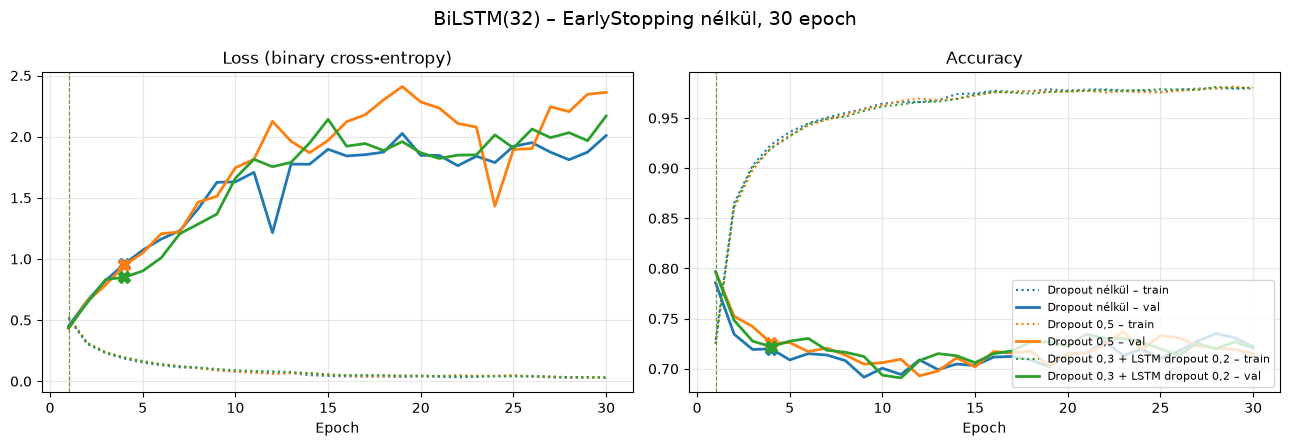

In [6]:
curves = {}
for label, kw in [("Dropout nélkül", dict(dropout=0.0)),
                  ("Dropout 0,5", dict(dropout=0.5)),
                  ("Dropout 0,3 + LSTM dropout 0,2", dict(dropout=0.3, lstm_dropout=0.2))]:
    dp.set_seeds(42)
    model = build_model(**base, **kw)
    history, sec = dp.fit(model, data, epochs=30, use_early_stopping=False)
    curves[label] = history
    h = history.history
    print(f"{label:32s} legjobb val_loss: {min(h['val_loss']):.4f} (epoch {dp.best_epoch(history)}),"
          f" 30. epoch val_loss: {h['val_loss'][-1]:.4f}, train acc: {h['accuracy'][-1]:.4f}, idő: {sec:.0f} s")
dp.plot_history(curves, f"{'Bi' if best_bi else ''}LSTM({best_units}) – EarlyStopping nélkül, 30 epoch"); plt.show()

**Megfigyelés:** a legjobb val_loss mindhárom esetben **már az 1. epoch után** jön (0,43–0,45). Utána a train accuracy 98% fölé megy, a val_loss viszont 30 epoch alatt 2,0–2,4-re nő. A BiLSTM tehát még gyorsabban tanul túl, mint a baseline (ott a 2. epochnál volt a minimum). A Dropout ezen a görbén nem tolja ki a minimumot, csak az 1. epoch utáni val_loss-t javítja kicsit (0,452 → 0,432–0,437). Itt is az **EarlyStopping a fő védekezés**: a restore_best_weights az 1. epoch súlyait tartja meg.

## Végső modell és kiértékelés a teszthalmazon
A beállítást a validációs eredmények alapján választjuk (legmagasabb átlagos val_acc mindhárom kísérletből). A teszthalmazt csak ez az egy modell látja, ez kerül a közös táblába (`results/bilstm.json`).

In [7]:
all_exp = pd.concat([exp1.assign(kísérlet=1), exp2.assign(kísérlet=2), exp3.assign(kísérlet=3)], ignore_index=True)
display(all_exp.sort_values("val_acc", ascending=False)[["kísérlet"] + SHOW].head(5)
        .style.format(fmt).hide(axis="index"))
best = all_exp.sort_values("val_acc", ascending=False).iloc[0]
final_params = {"units": int(best["units"]), "bidirectional": bool(best["bidirectional"]),
                "dropout": float(best["dropout"]), "lstm_dropout": float(best["lstm_dropout"]),
                "recurrent_dropout": float(best["recurrent_dropout"])}
print("Választott beállítás:", best["beállítás"], final_params)

dp.set_seeds(42)
final_model = build_model(**final_params)
final_history, final_seconds = dp.fit(final_model, data)
test_result = dp.evaluate(final_model, data, split="test")
print(f"Teszt accuracy: {test_result['accuracy']:.4f}   F1: {test_result['f1']:.4f}   "
      f"epochok: {len(final_history.history['loss'])} (legjobb: {dp.best_epoch(final_history)})   "
      f"idő: {final_seconds:.1f} s   paraméterek: {final_model.count_params():,}")

kísérlet,beállítás,paraméterek,val_acc,±acc,val_f1,val_loss,legjobb epoch,idő (s),s/epoch
3,Dropout 0.3,"1,223,513",0.7932,0.0052,0.7838,0.4393,1.0,20.1,5.03
2,32 egység,"1,223,513",0.7932,0.0052,0.7838,0.4393,1.0,20.6,5.16
3,Dropout 0.3 + LSTM dropout 0.2,"1,223,513",0.7921,0.0042,0.7811,0.4368,1.0,22.8,5.70
3,Dropout 0.5,"1,223,513",0.7907,0.0056,0.7817,0.4327,1.0,20.5,5.13
3,Dropout 0.3 + LSTM dropout/recurrent 0.2,"1,223,513",0.7858,0.0141,0.7748,0.4337,1.0,940.9,235.21


Választott beállítás: Dropout 0.3 {'units': 32, 'bidirectional': True, 'dropout': 0.3, 'lstm_dropout': 0.0, 'recurrent_dropout': 0.0}


Teszt accuracy: 0.7700   F1: 0.7545   epochok: 4 (legjobb: 1)   idő: 18.0 s   paraméterek: 1,223,513


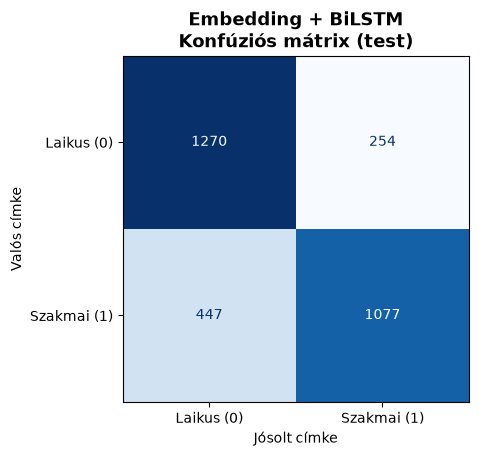

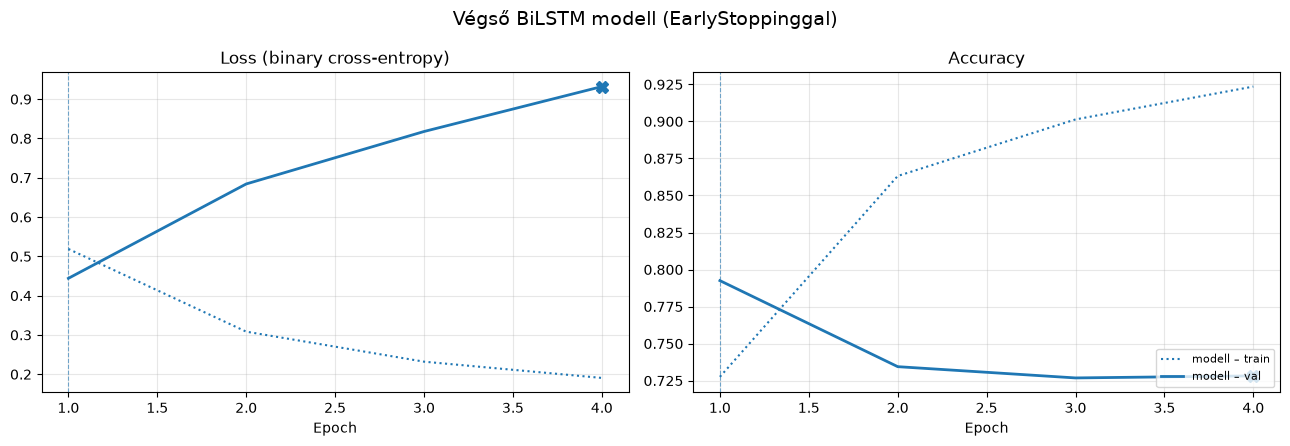

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_34 (Embedding)        │ (None, 48, 100)        │     1,189,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_31                │ (None, 64)             │        34,048 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,670,541 (14.00 MB)

 Trainable params: 1,223,513 (4.67 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,447,028 (9.33 MB)

In [8]:
fig, ax = plt.subplots(figsize=(5, 4.5))
dp.plot_confusion(test_result["confusion_matrix"], "Embedding + BiLSTM\nKonfúziós mátrix (test)", ax=ax); plt.show()
dp.plot_history(final_history, "Végső BiLSTM modell (EarlyStoppinggal)"); plt.show()
final_model.summary()

### Seed-érzékenység
Tájékoztató adat, a választásban nem vett részt: ugyanez a beállítás a három seeddel a teszthalmazon. Így látszik, mekkora eltérés számít zajnak az összehasonlításban.

In [9]:
seed_scores = []
for seed in SEEDS:
    dp.set_seeds(seed)
    m = build_model(**final_params)
    dp.fit(m, data)
    r = dp.evaluate(m, data, split="test")
    seed_scores.append((seed, r["accuracy"], r["f1"]))
seed_df = pd.DataFrame(seed_scores, columns=["seed", "test_acc", "test_f1"])
display(seed_df.round(4))
print(f"Átlag: acc {seed_df.test_acc.mean():.4f} ± {seed_df.test_acc.std():.4f},  F1 {seed_df.test_f1.mean():.4f} ± {seed_df.test_f1.std():.4f}")

,seed,test_acc,test_f1
0,42,0.7700,0.7545
1,43,0.7789,0.7735
2,44,0.7779,0.7634


Átlag: acc 0.7756 ± 0.0049,  F1 0.7638 ± 0.0095


### Adatok az LSTM vs. GRU összevetéshez (Attilának)
A közös beállítás (Bidirectional, 64 egység, Dropout 0,3, batch 64) validációs eredménye, paraméterszáma és tanítási ideje az 1. kísérletből, valamint a 32/64/128 egységes futások. Ezek a `results/bilstm.json` `hyperparams.shared_setup` mezőjébe is bekerülnek.

In [10]:
shared_row = exp1[exp1.bidirectional].iloc[0]
shared_setup = {
    "units": 64, "dropout": 0.3, "batch_size": dp.BATCH_SIZE, "embed_dim": dp.EMBED_DIM,
    "params": int(shared_row["paraméterek"]),
    "val_acc_mean": round(float(shared_row["val_acc"]), 4), "val_acc_std": round(float(shared_row["±acc"]), 4),
    "train_seconds_mean": round(float(shared_row["idő (s)"]), 2),
    "sec_per_epoch": round(float(shared_row["s/epoch"]), 3),
    "units_sweep": {int(r.units): {"params": int(r["paraméterek"]), "val_acc": round(float(r.val_acc), 4),
                                   "sec": round(float(r["idő (s)"]), 2)} for _, r in exp2.iterrows()},
}
shared_setup

{'units': 64,
 'dropout': 0.3,
 'batch_size': 64,
 'embed_dim': 100,
 'params': 1274009,
 'val_acc_mean': 0.7833,
 'val_acc_std': 0.0033,
 'train_seconds_mean': 19.78,
 'sec_per_epoch': 4.945,
 'units_sweep': {32: {'params': 1223513, 'val_acc': 0.7932, 'sec': 20.65},
  64: {'params': 1274009, 'val_acc': 0.7833, 'sec': 19.9},
  128: {'params': 1424153, 'val_acc': 0.7674, 'sec': 19.76}}}

In [11]:
path = dp.save_result(
    key="bilstm", name="Embedding + BiLSTM", model=final_model,
    history=final_history, result=test_result, train_seconds=final_seconds, data=data,
    params={**final_params, "shared_setup": shared_setup},
    notes=f"3 seed teszt átlag: acc {seed_df.test_acc.mean():.4f} ± {seed_df.test_acc.std():.4f}",
)
print("Mentve:", path)

Mentve: /home/kiskatsa/Projekt1/results/bilstm.json


## Összefoglalás

| | Embedding + GAP (baseline) | Embedding + BiLSTM (ez) |
|---|---|---|
| Teszt accuracy (seed 42) | 0,8071 | 0,7700 |
| Teszt F1 (seed 42) | 0,8044 | 0,7545 |
| Teszt acc, 3 seed átlaga | 0,7964 ± 0,0100 | 0,7756 ± 0,0049 |
| Paraméterek | 1 195 929 | 1 223 513 |
| Tanítási idő | 6,9 s (CPU) | 18,0 s (RTX 4060 GPU) |
| Legjobb epoch | 2 | 1 |

- **Végső beállítás** (val alapján): `Bidirectional(LSTM(32))`, Dropout 0,3, LSTM dropout/recurrent_dropout nélkül, `mask_zero=True`.
- A BiLSTM ezen a feladaton **~2 százalékponttal gyengébb a baseline-nál**, pedig lassabb és bonyolultabb. A szakmai és a laikus mondatot itt főleg a **szókincs** különbözteti meg (szakszavak jelenléte), nem a szórend. Ehhez az átlagolt embedding (GAP) elég, a szekvenciális modell pedig csak gyorsabban túltanul a kis train halmazon.
- Kísérletek: Bidirectional > sima LSTM (+0,5 pp); 32 > 64 > 128 egység; a Dropout réteg (0,3) +2 pp-t ad; az LSTM saját `dropout`/`recurrent_dropout` paramétere nem javít, a `recurrent_dropout` viszont ~47-szer lassabb, mert kikapcsolja a cuDNN-t.
- **Attilának (LSTM vs. GRU):** a közös beállítás (Bidirectional, 64 egység, Dropout 0,3, batch 64): 1 274 009 paraméter, val_acc 0,7833 ± 0,0033, ~19,8 s tanítás (~4,9 s/epoch, GPU). A 32/64/128 egységes futások a `results/bilstm.json` → `hyperparams.shared_setup` mezőben vannak.
- Környezet: TensorFlow 2.21.0, Python 3.13, NVIDIA RTX 4060 Laptop GPU. A teszt-ujjlenyomat (`cefa7c9f57300365`) egyezik a baseline-éval. A tanítási idő ezért GPU-n mért, nem vethető össze közvetlenül a baseline CPU-s idejével.